# Epithelial reintegration, malignancy calling and clustering


## Setup

In [1]:
import gc
import os
import re
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp

import scanpy as sc
import anndata as ad
import infercnvpy as cnv
import scvi

import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D

import rpy2.robjects as ro
import rpy2.rinterface_lib.callbacks as rcb
import logging



/opt/miniconda3/envs/cap/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Error importing in API mode: ImportError("dlopen(/opt/miniconda3/envs/cap/lib/python3.11/site-packages/_rinterface_cffi_api.abi3.so, 0x0002): Library not loaded: /Library/Frameworks/R.framework/Versions/4.5-arm64/Resources/lib/libRblas.dylib\n  Referenced from: <1984CB9B-890E-3855-A246-270AC6AC4C62> /opt/miniconda3/envs/cap/lib/python3.11/site-packages/_rinterface_cffi_api.abi3.so\n  Reason: tried: '/Library/Frameworks/R.framework/Versions/4.5-arm64/Resources/lib/libRblas.dylib' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/Library/Frameworks/R.framework/Versions/4.5-arm64/Resources/lib/libRblas.dylib' (no such file), '/Library/Frameworks/R.framework/Versions/4.5-arm64/Resources/lib/libRblas.dylib' (no such file)")
Trying t

In [2]:
# for reproducibility
np.random.seed(0)
scvi.settings.seed = 0
scvi.settings.num_workers = 4

sc.settings.verbosity = 2
rcb.logger.setLevel(logging.ERROR)

Seed set to 0


In [3]:
sns.set_theme(style="whitegrid", context="paper", palette="colorblind")

plt.rcParams.update({
    "font.size": 20,
    "axes.titlesize": 20,
    "axes.labelsize": 16,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.dpi": 300,
})

In [4]:

target_genes = ["ROR1", "ROR2", "EGFR", "ERBB2", "EPCAM"]

In [5]:
# paths; set CAP_PROJECT to run this outside the author's machine
project = Path(os.environ.get("CAP_PROJECT", "~/Downloads/1105_Project_Nowotny")).expanduser()

data_dir = project / "Data"
fig_dir = project / "Figures"
df_dir = project / "Dataframe_Saves"
save_dir = project / "Adata_Saves"
model_dir = project / "scvi_epithelial_model"
notebook_dir = project / "Nina_notebooks_Aug2026"

for d in [fig_dir, df_dir, save_dir, model_dir]:
    d.mkdir(parents=True, exist_ok=True)

# keep every scanpy figure in the same place as the plt.savefig output
sc.settings.figdir = fig_dir

gavish_file = notebook_dir / "Gavish_cell_state_signature.xlsx"
gencode_file = data_dir / "gencode.v50.annotation.gtf.gz"

for f in [gavish_file, gencode_file]:
    assert f.exists(), f

# show paths relative to the project root, so no absolute path is ever printed
def rel(path):
    return Path(path).relative_to(project)

## Load the epithelial compartment

In [6]:
epi = sc.read_h5ad(save_dir / "epithelial.h5ad")

print(epi)
print(epi.obs["condition"].value_counts().to_string())

AnnData object with n_obs × n_vars = 129599 × 28552
    obs: 'sample', 'condition', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'S_score', 'G2M_score', 'phase', 'doublet_score', 'doublet_class', 'batch', 'patient', 'scVI_leiden', 'sample_short', 'celltypist_pal_label', 'celltypist_pal_conf', 'cl_annotation'
    var: 'gene_id', 'feature_type', 'mt', 'ribo', 'hb', 'n_cells', 'binomial_deviance', 'highly_variable'
    uns: 'celltypist_pal_label_colors', 'cl_annotation_colors', 'condition_colors', 'neighbors', 'patient_colors', 'rank_genes_groups', 'sample_colors', 'sample_short_colors', 'scVI_leiden', 'scVI_leiden_colors', 'umap'
    obsm: 'X_pca', 'X_scVI', 'X_umap'
    layers: 'counts', 'log1p', 'lognorm'
    obsp: 'connectivities

In [7]:
# the atlas embedding from 002 is kept for reference and renamed, so that X_scVI / X_umap can hold the epithelial-only representation built below
for key, new_key in [("X_scVI", "X_scVI_atlas"), ("X_umap", "X_umap_atlas"),
                     ("X_pca", "X_pca_atlas")]:
    if key in epi.obsm:
        epi.obsm[new_key] = epi.obsm.pop(key)

# drop atlas-level results that no longer describe this object
for key in ["neighbors", "umap", "rank_genes_groups", "hvg", "scVI_leiden", "scVI_leiden_colors"]:
    epi.uns.pop(key, None)

epi.obs = epi.obs.drop(columns=[c for c in ["scVI_leiden"] if c in epi.obs.columns])

# the atlas gene selection is kept under its own name; highly_variable is re-derived below for the epithelial compartment
epi.var = epi.var.rename(columns={
    "highly_variable": "highly_variable_atlas",
    "highly_variable_rank": "highly_variable_rank_atlas",
    "highly_variable_nbatches": "highly_variable_nbatches_atlas",
})

epi.obsp.clear()

print(list(epi.obsm.keys()))

['X_scVI_atlas', 'X_umap_atlas', 'X_pca_atlas']


In [8]:
# counts must be untouched integers; every downstream threshold depends on it
assert "counts" in epi.layers

counts_data = epi.layers["counts"].data
assert np.allclose(counts_data, np.round(counts_data)), "counts layer is not integer"

# positive-cell counts recorded here are re-checked at the end of the notebook
baseline_positive = {
    g: int((np.asarray(epi[:, g].layers["counts"].todense()).ravel() > 0).sum())
    for g in target_genes
}

print(baseline_positive)

{'ROR1': 1171, 'ROR2': 2689, 'EGFR': 13076, 'ERBB2': 36641, 'EPCAM': 62303}


## Gene filtering and normalisation

In [9]:
# the shape of the object as it arrives from 002; the guards at the end of the notebook check against this, so a stray filter anywhere below is caught
n_cells_loaded = epi.n_obs
n_genes_loaded = epi.n_vars

epi.X = epi.layers["counts"].copy()

sc.pp.filter_genes(epi, min_cells=3)

n_genes_removed = n_genes_loaded - epi.n_vars

print(f"loaded:   {n_cells_loaded:,} cells x {n_genes_loaded:,} genes")
print(f"filtered: {n_genes_removed:,} genes in fewer than {3} epithelial cells")
print(f"master:   {epi.n_obs:,} cells x {epi.n_vars:,} genes")

filtered out 1195 genes that are detected in less than 3 cells
loaded:   129,599 cells x 28,552 genes
filtered: 1,195 genes in fewer than 3 epithelial cells
master:   129,599 cells x 27,357 genes


In [10]:
# X holds log-normalised expression from here on; raw counts stay in layers
sc.pp.normalize_total(epi, target_sum=1e4)
sc.pp.log1p(epi)

epi.layers["lognorm"] = epi.X.copy()

# 002 stored lognorm twice under two names; keep one
epi.layers.pop("log1p", None)

print(list(epi.layers.keys()))

normalizing counts per cell
    finished (0:00:00)
['counts', 'lognorm']


In [11]:
# the master shape that must survive inferCNV, scVI and clustering unchanged
n_cells_start = epi.n_obs
n_genes_start = epi.n_vars

assert n_cells_start == n_cells_loaded
assert n_genes_start == n_genes_loaded - n_genes_removed

## Highly variable genes

Binomial deviance (`scry`) computed per sample and aggregated by the maximum
across samples, so that a gene deviant in a single condition is retained.
Mitochondrial, ribosomal and haemoglobin genes are excluded before ranking.
Cell-cycle genes are deliberately **not** excluded here: proliferation is a
malignant cell state of interest.

In [12]:
%load_ext rpy2.ipython

In [13]:
%%R
suppressPackageStartupMessages({
    library(Matrix)
    library(SingleCellExperiment)
    library(scry)
})

In [14]:
def scipy_to_dgc(matrix):
    # transfer a scipy sparse matrix to R as a dgCMatrix
    matrix = sp.csc_matrix(matrix)
    return ro.r["new"](
        "dgCMatrix",
        i=ro.IntVector(matrix.indices),
        p=ro.IntVector(matrix.indptr),
        x=ro.FloatVector(matrix.data),
        Dim=ro.IntVector(matrix.shape),
    )

In [15]:
samples = epi.obs["sample"].astype(str).unique().tolist()

deviance = pd.DataFrame(index=epi.var_names, columns=samples, dtype=float)

for sample in samples:

    sub = epi[epi.obs["sample"].astype(str) == sample]

    ro.globalenv["raw_counts"] = scipy_to_dgc(sub.layers["counts"].T)
    ro.globalenv["gene_names"] = ro.StrVector(sub.var_names.tolist())
    ro.globalenv["cell_names"] = ro.StrVector(sub.obs_names.tolist())

    ro.r('''
        rownames(raw_counts) <- gene_names
        colnames(raw_counts) <- cell_names

        sce <- SingleCellExperiment(assays = list(counts = raw_counts))
        sce <- devianceFeatureSelection(sce)

        binomial_deviance <- rowData(sce)$binomial_deviance
    ''')

    deviance[sample] = np.asarray(ro.r["binomial_deviance"])

    ro.r("rm(raw_counts, sce, binomial_deviance); gc()")

    print(f"{sample}: {sub.n_obs:,} cells")

epi.var["binomial_deviance"] = deviance.max(axis=1)

assert epi.var["binomial_deviance"].notna().all()

GSM4909295_ER-AH0319: 567 cells
GSM4909296_ER-MH0001: 5,059 cells
GSM4909302_ER-MH0025: 3,713 cells
GSM4909305_ER-MH0029-7C: 2,037 cells
GSM4909306_ER-MH0029-9C: 5,841 cells
GSM4909300_ER-MH0032: 495 cells
GSM4909307_ER-MH0040: 4,989 cells
GSM4909301_ER-MH0042: 2,704 cells
GSM4909309_ER-MH0043-T: 2,582 cells
GSM4909311_ER-MH0056-T: 2,901 cells
GSM4909313_ER-MH0064-T: 2,944 cells
GSM4909299_ER-MH0114-T3: 5,777 cells
GSM4909297_ER-MH0125: 5,408 cells
GSM4909303_ER-MH0151: 712 cells
GSM4909304_ER-MH0163: 5,074 cells
GSM4909315_ER-MH0167-T: 4,824 cells
GSM4909317_ER-MH0173-T: 2,608 cells
GSM4909298_ER-PM0360: 1,825 cells
GSM4909289_HER2-AH0308: 3,029 cells
GSM4909291_HER2-MH0031: 1,453 cells
GSM4909292_HER2-MH0069: 239 cells
GSM4909293_HER2-MH0161: 3,854 cells
GSM4909294_HER2-MH0176: 4,979 cells
GSM4909290_HER2-PM0337: 2,943 cells
GSM4909272_N-MH0021-Total: 1,228 cells
GSM4909268_N-MH0023-Total: 4,055 cells
GSM4909263_N-MH0064-Total: 716 cells
GSM4909266_N-MH0169-Total: 717 cells
GSM490927

In [16]:
# genes excluded from ranking, but not from the object
for col in ["mt", "ribo", "hb"]:
    assert col in epi.var.columns, col

exclude = epi.var[["mt", "ribo", "hb"]].any(axis=1)

print(f"excluded from ranking: {int(exclude.sum()):,}")

excluded from ranking: 122


In [17]:
ranked = (
    epi.var.loc[~exclude, "binomial_deviance"]
    .sort_values(ascending=False)
    .index
)

deviant_genes = ranked[:4000]

print(f"deviance-ranked genes: {len(deviant_genes):,}")

deviance-ranked genes: 4,000


In [18]:
# protected genes: the four antigen targets plus every Gavish cancer meta-programme gene, retained irrespective of deviance rank
gavish_sheet = pd.read_excel(gavish_file, sheet_name="Cancer MPs")

gavish_sheet.columns = (
    gavish_sheet.columns.astype(str).str.replace(r"\s+", " ", regex=True).str.strip()
)

gavish_states = {}
mp_id_to_name = {}

for state in gavish_sheet.columns:

    genes = gavish_sheet[state].dropna().astype(str).str.strip()
    genes = genes[genes.ne("")].unique().tolist()

    mp_id = re.match(r"^(MP\d+)\b", state).group(1)

    gavish_states[state] = genes
    mp_id_to_name[mp_id] = state

assert len(gavish_states) == 41

gavish_genes = sorted({g for genes in gavish_states.values() for g in genes})

print(f"meta-programmes: {len(gavish_states)}")
print(f"unique Gavish genes: {len(gavish_genes):,}")

meta-programmes: 41
unique Gavish genes: 1,547


In [19]:
protected = sorted(set(target_genes) | set(gavish_genes))
protected_present = [g for g in protected if g in epi.var_names]

print(f"protected genes present: {len(protected_present):,} / {len(protected):,}")

protected genes present: 1,478 / 1,551


In [20]:
# two feature sets are recorded:   highly_variable_deviance : the 4,000 deviance-ranked genes, unbiased   highly_variable          : those plus the protected genes, used by scVI                              because the Methods require them ALRA in 003c and the robustness appendix below both use the deviance-only set, so neither depends on the protected-gene decision.
epi.var["highly_variable_deviance"] = epi.var_names.isin(deviant_genes)

epi.var["highly_variable"] = (
    epi.var["highly_variable_deviance"] | epi.var_names.isin(protected_present)
)

n_hvg = int(epi.var["highly_variable"].sum())
n_hvg_deviance = int(epi.var["highly_variable_deviance"].sum())
n_protected_added = n_hvg - n_hvg_deviance

print(f"deviance-ranked genes:      {n_hvg_deviance:,}")
print(f"added by the protected list: {n_protected_added:,}")
print(f"scVI feature set:           {n_hvg:,} "
      f"({100 * n_protected_added / n_hvg:.1f}% protected)")

for gene in target_genes:
    assert epi.var.loc[gene, "highly_variable"], gene

pd.Series(epi.var_names[epi.var["highly_variable"]]).to_csv(
    df_dir / "epithelial_hvg_genes.csv", index=False, header=False
)

deviance-ranked genes:      4,000
added by the protected list: 588
scVI feature set:           4,588 (12.8% protected)


## inferCNV



Run on a copy of the object, so that the gene filtering required by inferCNV
does not shrink the master object. Coordinates come from GENCODE v50 joined on
Ensembl gene ID; symbol matching resolves far fewer genes.

In [22]:
# inferCNV needs log-normalised expression, the sample annotation and the gene coordinates. A full epi.copy() would also carry the counts layer and double peak memory for no benefit, so the working object is built slim.
cnv_adata = ad.AnnData(
    X=epi.layers["lognorm"].copy(),
    obs=epi.obs.copy(),
    var=epi.var.copy(),
)

print(f"inferCNV working object: {cnv_adata.n_obs:,} cells x {cnv_adata.n_vars:,} genes")

inferCNV working object: 129,599 cells x 27,357 genes


In [23]:
gtf = pd.read_csv(
    gencode_file,
    sep="\t",
    comment="#",
    header=None,
    names=["chromosome", "source", "feature", "start", "end",
           "score", "strand", "frame", "attribute"],
)

In [24]:

gencode = gtf[gtf["feature"] == "gene"].copy()

In [25]:

gencode["ensembl"] = (
    gencode["attribute"].str.extract(r'gene_id "([^"]+)"')[0].str.split(".").str[0]
)

In [26]:

gencode["gene_type"] = gencode["attribute"].str.extract(r'gene_type "([^"]+)"')[0]

In [27]:

gencode = gencode.drop_duplicates("ensembl").set_index("ensembl")

In [28]:

len(gencode)

78733

In [29]:

del gtf
gc.collect()

25

In [30]:
# join on stable Ensembl identifiers taken from the dataset's own annotation
ensembl = cnv_adata.var["gene_id"].astype(str).str.split(".").str[0]

In [31]:

cnv_adata.var["chromosome"] = ensembl.map(gencode["chromosome"]).values
cnv_adata.var["start"] = ensembl.map(gencode["start"]).values
cnv_adata.var["end"] = ensembl.map(gencode["end"]).values
cnv_adata.var["gene_type"] = ensembl.map(gencode["gene_type"]).values

resolved = cnv_adata.var["chromosome"].notna()

In [32]:
# free the large intermediates; nothing below uses them
del gencode
gc.collect()

28

In [33]:

resolved.sum(), cnv_adata.n_vars

(np.int64(26534), 27357)

In [34]:

cnv_adata.var.loc[~resolved, ["gene_id"]].to_csv(df_dir / "infercnv_unresolved_genes.csv")

In [35]:
# protein-coding autosomal genes only

In [36]:
autosomes = [f"chr{i}" for i in range(1, 23)]

keep = (
    cnv_adata.var["chromosome"].isin(autosomes)
    & cnv_adata.var["gene_type"].eq("protein_coding")
)

In [37]:

cnv_adata = cnv_adata[:, keep].copy()

In [38]:

cnv_adata.n_vars

17495

In [39]:
# gene families whose variation is not driven by copy number
problematic = (
    cnv_adata.var_names.str.startswith(
        ("MT-", "RPS", "RPL", "HLA-", "IGH", "IGK", "IGL", "KRT", "SPRR", "S100A")
    )
    | cnv_adata.var_names.isin(["MALAT1", "NEAT1"])
)

In [40]:

problematic.sum()

np.int64(230)

In [41]:

cnv_adata = cnv_adata[:, ~problematic].copy()

In [42]:

sc.pp.filter_genes(cnv_adata, min_cells=100)

filtered out 2366 genes that are detected in less than 100 cells


In [43]:

cnv_adata.n_vars

14899

In [44]:
# genomic ordering
cnv_adata.var["chromosome"] = cnv_adata.var["chromosome"].astype(str)
cnv_adata.var["chr_num"] = cnv_adata.var["chromosome"].str.replace("chr", "", regex=False).astype(int)

order = cnv_adata.var.sort_values(["chr_num", "start"]).index
cnv_adata = cnv_adata[:, order].copy()

assert cnv_adata.var_names.is_unique
assert (np.diff(cnv_adata.var["chr_num"].to_numpy()) >= 0).all()

In [45]:
# normal epithelium provides the diploid reference
reference = cnv_adata[cnv_adata.obs["condition"] == "N"].copy()

print(f"reference cells: {reference.n_obs:,} from {reference.obs['sample'].nunique()} samples")

reference cells: 26,425 from 13 samples


In [46]:
cnv_adata.obs["cnv_score"] = np.nan
cnv_adata.obs["cnv_signal"] = np.nan

x_cnv_full = None
failures = []

cnv_samples = cnv_adata.obs["sample"].astype(str).unique().tolist()

In [47]:
len(cnv_samples)

45

In [48]:
for sample in cnv_samples:

    print(f"\n{sample}")

    target = refs = combined = None

    try:
        target = cnv_adata[cnv_adata.obs["sample"].astype(str) == sample].copy()
        condition = str(target.obs["condition"].iloc[0])

        # a normal sample is never its own reference
        if condition == "N":
            refs = reference[reference.obs["sample"].astype(str) != sample].copy()
        else:
            refs = reference.copy()

        assert refs.n_obs > 0

        refs.obs["cnv_reference"] = "reference"
        target.obs["cnv_reference"] = "query"

        combined = sc.concat([refs, target], join="inner", merge="same")

        print(f"  {condition}: {target.n_obs:,} query, {refs.n_obs:,} reference")

        # X holds log-normalised expression, so no layer is passed
        cnv.tl.infercnv(
            combined,
            reference_key="cnv_reference",
            reference_cat=["reference"],
            window_size=100,
            step=10,
            dynamic_threshold=0.5,
            exclude_chromosomes=("chrX", "chrY"),
            n_jobs=1,
        )

        x_cnv = combined.obsm["X_cnv"]
        x_cnv = x_cnv.toarray() if sp.issparse(x_cnv) else np.asarray(x_cnv)
        x_cnv = x_cnv.astype(np.float32)

        query = combined.obs["cnv_reference"].eq("query").to_numpy()
        query_names = combined.obs_names[query]
        x_query = x_cnv[query]

        # map each inferCNV window to its chromosome
        chr_pos = sorted(combined.uns["cnv"]["chr_pos"].items(), key=lambda kv: kv[1])
        n_windows = x_query.shape[1]

        chr_labels = np.empty(n_windows, dtype=object)

        for i, (chrom, start) in enumerate(chr_pos):
            end = chr_pos[i + 1][1] if i + 1 < len(chr_pos) else n_windows
            chr_labels[start:end] = chrom

        # root-mean-square burden per chromosome, weighted by window count, so that long chromosomes do not dominate the cell-level score
        chrom_scores = []
        chrom_weights = []

        for chrom in pd.unique(chr_labels):
            idx = np.flatnonzero(chr_labels == chrom)
            chrom_scores.append(np.sqrt(np.mean(x_query[:, idx] ** 2, axis=1)))
            chrom_weights.append(len(idx))

        chrom_scores = np.column_stack(chrom_scores)
        chrom_weights = np.asarray(chrom_weights, dtype=float)
        chrom_weights /= chrom_weights.sum()

        cnv_score = np.average(chrom_scores, axis=1, weights=chrom_weights)
        cnv_signal = np.max(np.abs(x_query), axis=1)

        cnv_adata.obs.loc[query_names, "cnv_score"] = cnv_score
        cnv_adata.obs.loc[query_names, "cnv_signal"] = cnv_signal

        if x_cnv_full is None:
            x_cnv_full = np.full((cnv_adata.n_obs, n_windows), np.nan, dtype=np.float32)

        if "cnv" not in cnv_adata.uns:
            cnv_adata.uns["cnv"] = dict(combined.uns["cnv"])

        x_cnv_full[cnv_adata.obs_names.get_indexer(query_names)] = x_query

        print(f"  median burden {np.median(cnv_score):.4f}")

    except Exception as error:
        print(f"  failed: {error}")
        failures.append({"sample": sample, "error": str(error)})

    finally:
        del target, refs, combined
        gc.collect()


GSM4909295_ER-AH0319
  ER+: 567 query, 26,425 reference


100%|██████████| 6/6 [00:09<00:00,  1.65s/it]


  median burden 0.0553

GSM4909296_ER-MH0001
  ER+: 5,059 query, 26,425 reference


100%|██████████| 7/7 [00:10<00:00,  1.55s/it]


  median burden 0.0476

GSM4909302_ER-MH0025
  ER+: 3,713 query, 26,425 reference


...

  median burden 0.0547

GSM4909283_TN-SH0106
  TN: 54 query, 26,425 reference


100%|██████████| 6/6 [00:22<00:00,  3.72s/it]


  median burden 0.0423

GSM4909287_TN-B1-Tum0554
  TN: 2,684 query, 26,425 reference


100%|██████████| 6/6 [00:21<00:00,  3.53s/it]


  median burden 0.0552


In [49]:
# a failed sample would leave cnv_score NaN, fall below the threshold and be silently called non-malignant, so stop rather than continue
failures = pd.DataFrame(failures)

if not failures.empty:
    failures.to_csv(df_dir / "infercnv_failed_samples.csv", index=False)
    raise RuntimeError(f"inferCNV failed for {len(failures)} sample(s)")

assert cnv_adata.obs[["cnv_score", "cnv_signal"]].notna().all().all()

print("all samples completed")

all samples completed


In [50]:
# the burden should not simply track sequencing depth
r = np.corrcoef(cnv_adata.obs["cnv_score"], cnv_adata.obs["total_counts"])[0, 1]

print(f"cnv_score vs total_counts: r = {r:.3f}")

cnv_score vs total_counts: r = -0.193


In [51]:
cnv_adata.obs.groupby("condition", observed=True)["cnv_score"].describe().round(4)

,count,mean,std,min,25%,50%,75%,max
condition,,,,,,,,
N,26425.0,0.0387,0.0079,0.0159,0.0329,0.0396,0.0445,0.0720
TN,26617.0,0.0557,0.0093,0.0209,0.0498,0.0569,0.0623,0.1745
HER2+,16497.0,0.0527,0.0067,0.0273,0.0483,0.0525,0.0566,0.1124
ER+,60060.0,0.0507,0.0062,0.0241,0.0468,0.0506,0.0544,0.0999


## Malignancy calling

In [52]:
# malignant = CNV burden above the normal epithelial reference. Calling malignancy from the sample label alone would count non-malignant epithelium inside a tumour sample as malignant.
normal_scores = cnv_adata.obs.loc[cnv_adata.obs["condition"] == "N", "cnv_score"]

cnv_threshold = float(normal_scores.quantile(0.95))

cnv_adata.obs["cnv_high"] = cnv_adata.obs["cnv_score"] > cnv_threshold
cnv_adata.obs["malignant"] = cnv_adata.obs["cnv_high"] & cnv_adata.obs["condition"].ne("N")

print(f"threshold (q={0.95:.2f} of normal): {cnv_threshold:.4f}")
print(pd.crosstab(cnv_adata.obs["condition"], cnv_adata.obs["malignant"], margins=True))

threshold (q=0.95 of normal): 0.0504
malignant  False   True     All
condition                      
N          26425      0   26425
TN          7116  19501   26617
HER2+       6097  10400   16497
ER+        29415  30645   60060
All        69053  60546  129599


In [53]:
# sensitivity of the malignant fraction to the reference quantile
rows = []

for quantile in [0.90, 0.95, 0.99]:

    threshold = float(normal_scores.quantile(quantile))
    called = cnv_adata.obs["cnv_score"].gt(threshold) & cnv_adata.obs["condition"].ne("N")

    for condition in ["ER+", "HER2+", "TN"]:
        mask = cnv_adata.obs["condition"].eq(condition)
        rows.append({
            "quantile": quantile,
            "threshold": threshold,
            "condition": condition,
            "n_cells": int(mask.sum()),
            "n_malignant": int(called[mask].sum()),
            "malignant_fraction": float(called[mask].mean()),
        })

threshold_sensitivity = pd.DataFrame(rows)

print(threshold_sensitivity.round(4).to_string(index=False))

threshold_sensitivity.to_csv(df_dir / "infercnv_threshold_sensitivity.csv", index=False)

 quantile  threshold condition  n_cells  n_malignant  malignant_fraction
     0.90     0.0482       ER+    60060        40080              0.6673
     0.90     0.0482     HER2+    16497        12519              0.7589
     0.90     0.0482        TN    26617        21011              0.7894
     0.95     0.0504       ER+    60060        30645              0.5102
     0.95     0.0504     HER2+    16497        10400              0.6304
     0.95     0.0504        TN    26617        19501              0.7327
     0.99     0.0552       ER+    60060        12580              0.2095
     0.99     0.0552     HER2+    16497         5403              0.3275
     0.99     0.0552        TN    26617        15218              0.5717


In [54]:
sample_malignancy = (
    cnv_adata.obs
    .groupby(["sample", "condition"], observed=True)
    .agg(n_cells=("malignant", "size"),
         n_malignant=("malignant", "sum"),
         median_cnv=("cnv_score", "median"))
    .reset_index()
)

In [55]:

sample_malignancy["malignant_fraction"] = (
    sample_malignancy["n_malignant"] / sample_malignancy["n_cells"]
)

In [56]:

sample_malignancy.sort_values(["condition", "malignant_fraction"]).round(3)

,sample,condition,n_cells,n_malignant,median_cnv,malignant_fraction
0,GSM4909253_N-PM0092-Total,N,3164,0,0.037,0.000
1,GSM4909254_N-PM0019-Total,N,3830,0,0.038,0.000
2,GSM4909257_N-PM0095-Total,N,2215,0,0.034,0.000
3,GSM4909261_N-PM0230-Total,N,817,0,0.037,0.000
4,GSM4909263_N-MH0064-Total,N,716,0,0.043,0.000
5,GSM4909265_N-PM0233-Total,N,2065,0,0.037,0.000
6,GSM4909266_N-MH0169-Total,N,717,0,0.041,0.000
7,GSM4909268_N-MH0023-Total,N,4055,0,0.042,0.000
8,GSM4909270_N-PM0342-Total,N,4364,0,0.042,0.000
9,GSM4909271_N-MH288-Total,N,755,0,0.038,0.000


In [57]:

sample_malignancy.to_csv(df_dir / "infercnv_malignancy_by_sample.csv", index=False)

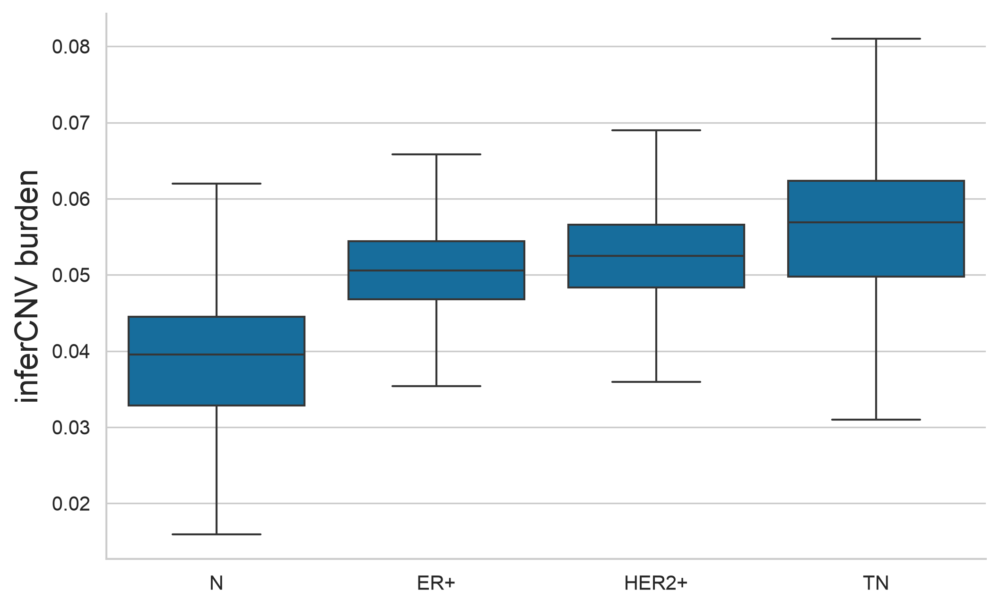

In [58]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.boxplot(
    data=cnv_adata.obs,
    x="condition",
    y="cnv_score",
    order=["N", "ER+", "HER2+", "TN"],
    showfliers=False,
    ax=ax,
)

ax.set_xlabel("")
ax.set_ylabel("inferCNV burden")
sns.despine()

plt.savefig(fig_dir / "infercnv_score_by_condition.png", dpi=300, bbox_inches="tight")
plt.show()

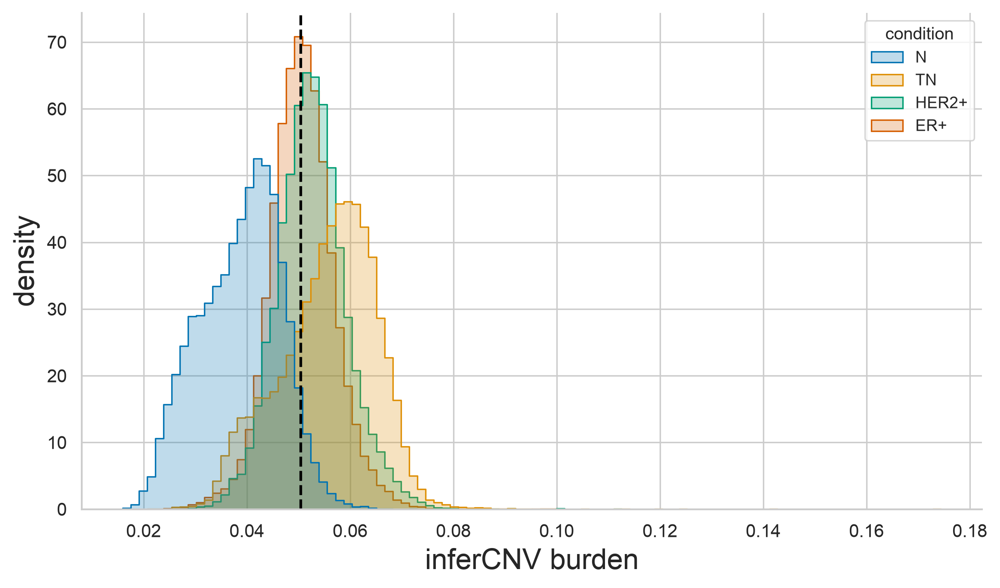

In [59]:
fig, ax = plt.subplots(figsize=(9, 5))

sns.histplot(
    data=cnv_adata.obs,
    x="cnv_score",
    hue="condition",
    bins=100,
    stat="density",
    common_norm=False,
    element="step",
    ax=ax,
)

ax.axvline(cnv_threshold, linestyle="--", linewidth=1.5, color="black")
ax.set_xlabel("inferCNV burden")
ax.set_ylabel("density")
sns.despine()

plt.savefig(fig_dir / "infercnv_threshold.png", dpi=300, bbox_inches="tight")
plt.show()

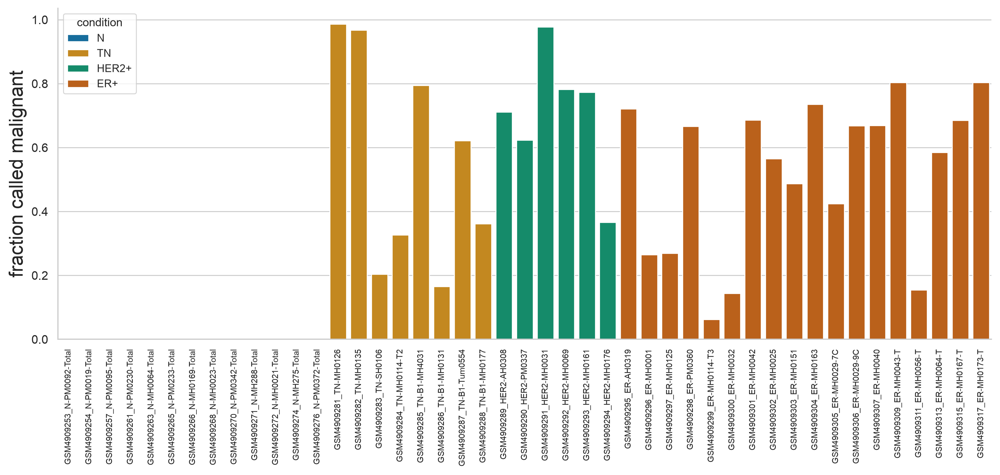

In [60]:
fig, ax = plt.subplots(figsize=(14, 5))

sns.barplot(
    data=sample_malignancy,
    x="sample",
    y="malignant_fraction",
    hue="condition",
    dodge=False,
    ax=ax,
)

ax.set_xlabel("")
ax.set_ylabel("fraction called malignant")
ax.tick_params(axis="x", rotation=90, labelsize=7)
sns.despine()

plt.savefig(fig_dir / "infercnv_malignant_fraction_by_sample.png", dpi=300, bbox_inches="tight")
plt.show()

In [61]:
# transfer the inferCNV results onto the master object
assert epi.obs_names.equals(cnv_adata.obs_names)

In [62]:

for col in ["cnv_score", "cnv_signal", "cnv_high", "malignant"]:
    epi.obs[col] = cnv_adata.obs[col].reindex(epi.obs_names)

In [63]:

epi.obs["cnv_high"] = epi.obs["cnv_high"].astype(bool)
epi.obs["malignant"] = epi.obs["malignant"].astype(bool)

In [64]:

epi.uns["malignancy_call"] = {
    "method": "infercnvpy",
    "reference": "normal epithelial cells, leave-one-sample-out for normal samples",
    "gene_annotation": "GENCODE v50, joined on Ensembl gene id",
    "expression_layer": "log-normalised expression",
    "window_size": 100,
    "step": 10,
    "dynamic_threshold": 0.5,
    "cnv_score": "chromosome-level rms burden weighted by window count",
    "normal_quantile": float(0.95),
    "threshold": cnv_threshold,
    "cnv_score_vs_total_counts_r": float(r),
}

In [65]:

epi.obs["malignant"].sum()

np.int64(60546)

In [66]:
cnv_adata.obsm["X_cnv"] = x_cnv_full

In [67]:

cnv_adata.write_h5ad(save_dir / "epithelial_infercnv.h5ad", compression="gzip")

In [68]:

del cnv_adata, reference, x_cnv_full
gc.collect()

7557

## scVI integration

In [69]:
epi_scvi = epi[:, epi.var["highly_variable"]].copy()

In [70]:

assert epi_scvi.n_obs == epi.n_obs
assert epi_scvi.n_vars == n_hvg

In [71]:
epi_scvi.shape

(129599, 4588)

In [72]:
# sample (library) identity is the batch covariate
scvi.model.SCVI.setup_anndata(epi_scvi, layer="counts", batch_key="sample")

In [73]:

model = scvi.model.SCVI(epi_scvi,n_latent=20,n_layers=2,gene_likelihood='nb',)

In [74]:
# free the large intermediates; nothing below uses them
del epi_scvi
gc.collect()

124

In [75]:
model

SCVI model with the following parameters: 
n_hidden: 128, n_latent: 20, n_layers: 2, dropout_rate: 0.1, dispersion: gene, gene_likelihood: nb, 
latent_distribution: normal.
Training status: Not Trained
Model's adata is minified?: False

In [76]:
# min_delta of 1.0 nat on the ELBO stops training once the remaining gain is small relative to the reconstruction term; it sets the epoch count reported
model.train(
    max_epochs=400,
    accelerator="mps",
    batch_size=1024,
    early_stopping=True,
    early_stopping_patience=20,
    early_stopping_min_delta=1.0,
)

/opt/miniconda3/envs/cap/lib/python3.11/site-packages/scvi/train/_trainrunner.py:98: UserWarning: `accelerator` has been set to `mps`. Please note that not all PyTorch/Jax operations are supported with this backend. as a result, some models might be slower and less accurate than usual. Please verify your analysis!Refer to https://github.com/pytorch/pytorch/issues/77764 for more details.
  accelerator, lightning_devices, device = parse_device_args(
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/opt/miniconda3/envs/cap/lib/python3.11/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/opt/miniconda3/envs/cap/

Epoch 162/400:  40%|████      | 162/400 [5:33:24<8:09:49, 123.48s/it, v_num=1, train_loss=2.89e+3] 
Monitored metric elbo_validation did not improve in the last 20 records. Best score: 2907.518. Signaling Trainer to stop.


In [77]:

n_epochs = model.history["elbo_train"].shape[0]

In [78]:

n_epochs

162

In [79]:
model.save(str(model_dir), overwrite=True)
model.history["elbo_train"].to_csv(df_dir / "scvi_epithelial_history.csv")

In [80]:

latent = model.get_latent_representation()

In [81]:

assert latent.shape == (epi.n_obs, 20)
assert np.isfinite(latent).all()

In [82]:

epi.obsm["X_scVI"] = latent

In [83]:

latent.shape

(129599, 20)

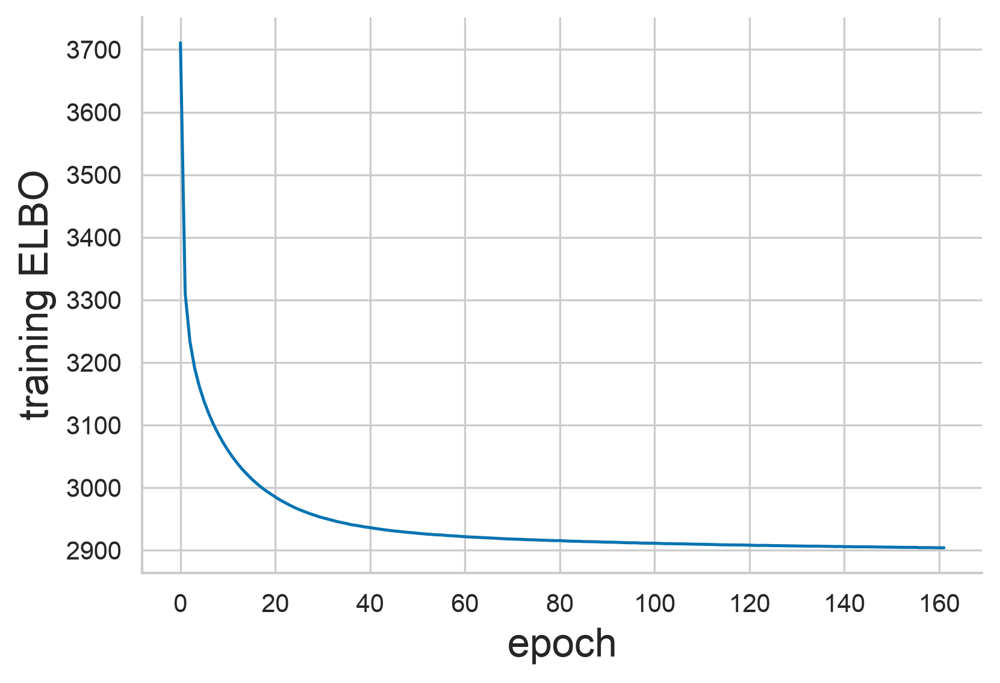

In [84]:
fig, ax = plt.subplots(figsize=(6, 4))

model.history["elbo_train"].plot(ax=ax, legend=False)

ax.set_xlabel("epoch")
ax.set_ylabel("training ELBO")
sns.despine()

plt.savefig(fig_dir / "scvi_epithelial_elbo.png", dpi=300, bbox_inches="tight")
plt.show()

## Neighbours, UMAP and Leiden clustering

In [85]:
sc.pp.neighbors(epi, use_rep="X_scVI", n_neighbors=30, random_state=0)

sc.tl.umap(epi, random_state=0)

computing neighbors
    finished (0:00:21)
computing UMAP
    finished (0:00:49)


In [86]:
from sklearn.metrics import adjusted_rand_score

In [ ]:
leiden_resolutions = [0.5, 1.0, 1.2, 1.5]

In [ ]:

for resolution in leiden_resolutions:

    sc.tl.leiden(
        epi,
        resolution=resolution,
        key_added=f"leiden_r{resolution}",
        flavor="igraph",
        n_iterations=2,
        directed=False,
        random_state=0,
    )

    print(f"resolution {resolution}: {epi.obs[f'leiden_r{resolution}'].nunique()} clusters")

running Leiden clustering
    finished (0:00:05)
resolution 0.5: 17 clusters
running Leiden clustering
    finished (0:00:05)
resolution 1.0: 22 clusters
running Leiden clustering
    finished (0:00:05)
resolution 1.2: 27 clusters
running Leiden clustering
    finished (0:00:05)
resolution 1.5: 32 clusters


In [ ]:

for resolution in leiden_resolutions[1:]:
    ari = adjusted_rand_score(
        epi.obs[f"leiden_r{0.5}"], epi.obs[f"leiden_r{resolution}"]
    )
    print(f"ARI {0.5} vs {resolution}: {ari:.3f}")

ARI 0.5 vs 1.0: 0.458
ARI 0.5 vs 1.2: 0.407
ARI 0.5 vs 1.5: 0.366


In [90]:
# the primary resolution defines the clusters used for programme assignment in 003b
epi.obs["epi_leiden"] = epi.obs[f"leiden_r{0.5}"].copy()

In [91]:

epi.obs["epi_leiden"].value_counts().sort_index()

epi_leiden
0     15590
1       255
2     18145
3     41304
4      8666
5       466
6        88
7      5755
8        62
9     11143
10     6268
11     6109
12     2190
13     8080
14     2119
15     3128
16      231
Name: count, dtype: int64

## Integration diagnostics

In [92]:
from sklearn.metrics import silhouette_score

In [93]:

rng = np.random.default_rng(0)

n_eval = min(20000, epi.n_obs)
eval_idx = rng.choice(epi.n_obs, size=n_eval, replace=False)

z_eval = epi.obsm["X_scVI"][eval_idx]
obs_eval = epi.obs.iloc[eval_idx]

bio_asw = silhouette_score(z_eval, obs_eval["cl_annotation"], metric="euclidean")
batch_asw = silhouette_score(z_eval, obs_eval["sample"], metric="euclidean")

print(f"annotation silhouette: {bio_asw:.3f}")
print(f"sample silhouette:     {batch_asw:.3f}")

annotation silhouette: 0.037
sample silhouette:     -0.067


In [94]:

pd.DataFrame({
    "metric": ["annotation_silhouette", "sample_silhouette"],
    "value": [bio_asw, batch_asw],
}).to_csv(df_dir / "scvi_epithelial_integration_metrics.csv", index=False)

In [95]:
# a cluster dominated by one sample is a candidate residual batch effect
sample_counts = pd.crosstab(epi.obs["epi_leiden"], epi.obs["sample"])
sample_fractions = sample_counts.div(sample_counts.sum(axis=1), axis=0)

p = sample_fractions.replace(0, np.nan)

cluster_composition = pd.DataFrame({
    "n_cells": sample_counts.sum(axis=1),
    "n_samples": (sample_counts > 0).sum(axis=1),
    "top_sample": sample_fractions.idxmax(axis=1),
    "top_sample_fraction": sample_fractions.max(axis=1),
    "sample_entropy": -(p * np.log(p)).sum(axis=1) / np.log(sample_fractions.shape[1]),
})

print(cluster_composition.sort_values("top_sample_fraction", ascending=False).round(3).to_string())

            n_cells  n_samples                 top_sample  top_sample_fraction  sample_entropy
epi_leiden                                                                                    
5               466          5     GSM4909289_HER2-AH0308                0.989           0.019
6                88          2       GSM4909303_ER-MH0151                0.989           0.016
16              231         11     GSM4909293_HER2-MH0161                0.926           0.108
8                62          6    GSM4909305_ER-MH0029-7C                0.887           0.136
1               255          6    GSM4909306_ER-MH0029-9C                0.733           0.185
14             2119         38    GSM4909299_ER-MH0114-T3                0.398           0.621
2             18145         45       GSM4909282_TN-MH0135                0.346           0.682
13             8080         26  GSM4909270_N-PM0342-Total                0.309           0.541
10             6268         37  GSM4909268_N-MH002

In [96]:

cluster_composition.to_csv(df_dir / "scvi_epithelial_cluster_sample_composition.csv")

In [97]:
cluster_malignancy = (
    epi.obs
    .groupby("epi_leiden", observed=True)
    .agg(n_cells=("malignant", "size"),
         n_malignant=("malignant", "sum"),
         median_cnv=("cnv_score", "median"))
)

In [98]:

cluster_malignancy["malignant_fraction"] = (
    cluster_malignancy["n_malignant"] / cluster_malignancy["n_cells"]
)

In [99]:

cluster_malignancy.sort_values("malignant_fraction", ascending=False).round(3)

,n_cells,n_malignant,median_cnv,malignant_fraction
epi_leiden,,,,
8,62,59,0.058,0.952
5,466,426,0.055,0.914
2,18145,15513,0.058,0.855
6,88,64,0.053,0.727
7,5755,4151,0.054,0.721
16,231,155,0.052,0.671
3,41304,25310,0.052,0.613
1,255,154,0.052,0.604
0,15590,8679,0.052,0.557


In [100]:

cluster_malignancy.to_csv(df_dir / "scvi_epithelial_cluster_malignancy.csv")

In [101]:
# canonical epithelial markers, to confirm the clusters are epithelial
marker_genes = [
    g for g in ["EPCAM", "KRT8", "KRT18", "KRT19", "KRT7", "KRT5", "KRT14", "KRT17", "MUC1"]
    if g in epi.var_names
]

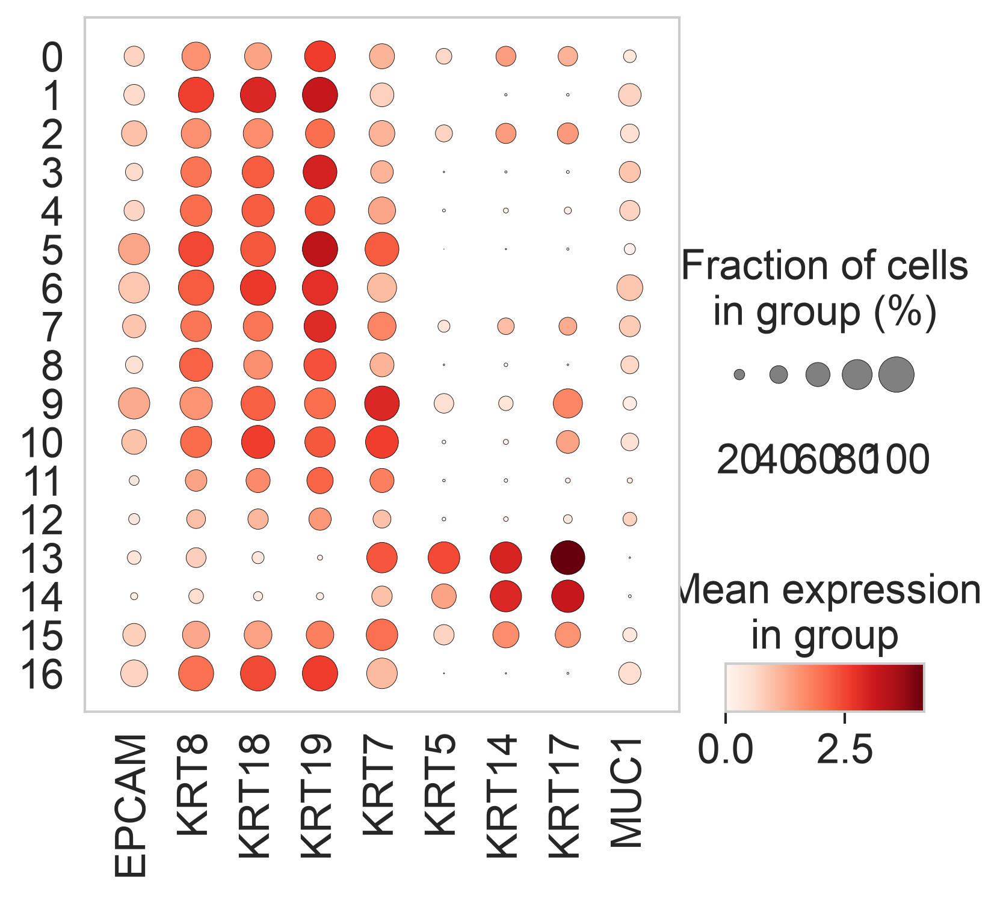

In [102]:

sc.pl.dotplot(
    epi,
    var_names=marker_genes,
    groupby="epi_leiden",
    layer="lognorm",
    use_raw=False,
    figsize=(6, 5),
    show=False,
)

plt.savefig(fig_dir / "epithelial_cluster_markers_dotplot.png", dpi=300, bbox_inches="tight")
plt.show()

## Figure 1a and related UMAPs

In [103]:
condition_palette = {
    "N": "#031A6B",
    "ER+": "#F46036",
    "HER2+": "#2CA02C",
    "TN": "#976391",
}

condition_order = ["TN", "HER2+", "ER+", "N"]

epi.obs["condition"] = pd.Categorical(
    epi.obs["condition"].astype(str), categories=condition_order, ordered=True
)

In [104]:

# set the colours on the object, so plotting a subset does not have to write them
epi.uns["condition_colors"] = [condition_palette[c] for c in condition_order]

In [105]:

epi.obs["cl_annotation"] = epi.obs["cl_annotation"].astype("category")

In [106]:

epi.obs["sample_short"] = (
    epi.obs["sample_short"].astype("category").cat.remove_unused_categories()
)

/opt/miniconda3/envs/cap/lib/python3.11/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


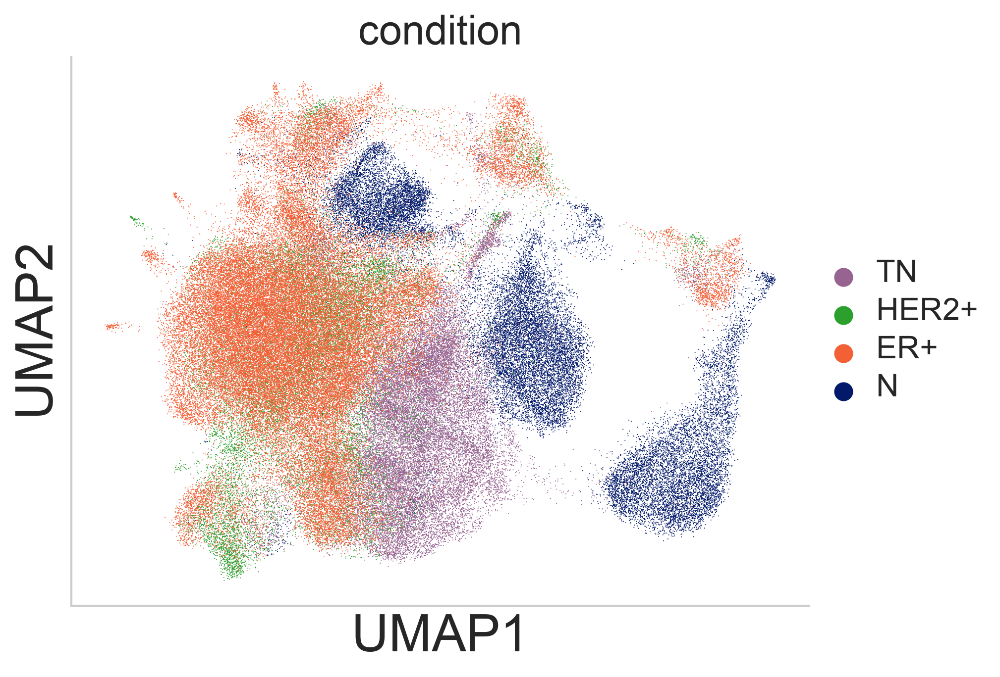

In [107]:
# draw N first so that the tumour conditions are not hidden underneath it
draw_order = ["N", "TN", "HER2+", "ER+"]
rank = {condition: i for i, condition in enumerate(draw_order)}

plot_idx = epi.obs["condition"].astype(str).map(rank).sort_values().index

sc.pl.umap(
    epi[plot_idx],
    color="condition",
    palette=condition_palette,
    frameon=True,
    show=False,
)

ax = plt.gca()
ax.spines[["top", "right"]].set_visible(False)
ax.set_xlabel("UMAP1", fontsize=25)
ax.set_ylabel("UMAP2", fontsize=25)
ax.tick_params(axis="both", labelsize=12)

legend = ax.get_legend()

if legend is not None:
    plt.setp(legend.get_texts(), fontsize=15)
    for handle in legend.legend_handles:
        handle.set_sizes([70])

plt.savefig(fig_dir / "epithelial_umap_condition.png", dpi=300, bbox_inches="tight")
plt.show()

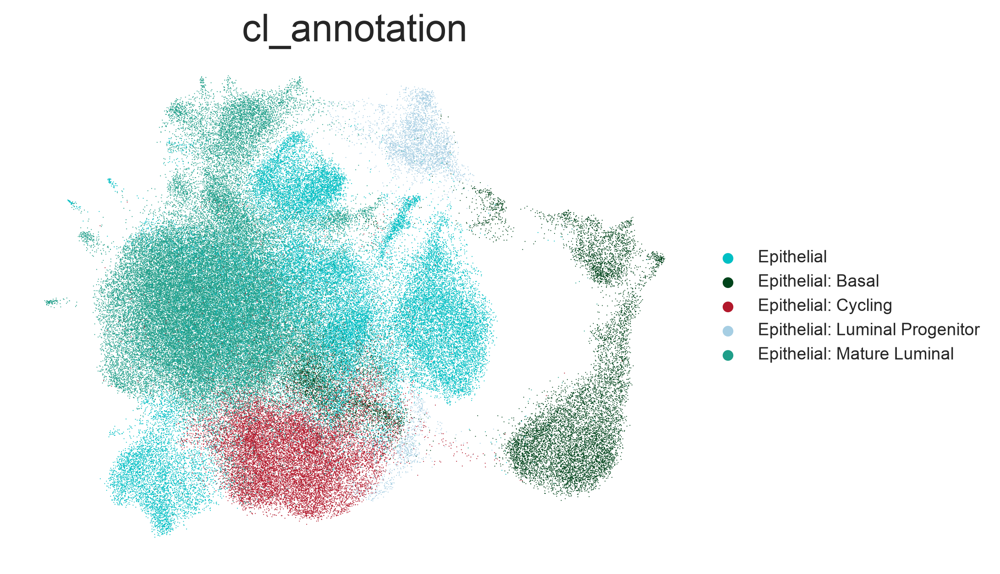

In [108]:
sc.pl.umap(epi, color="cl_annotation", frameon=False, show=False)

plt.savefig(fig_dir / "epithelial_umap_cl_annotation.png", dpi=300, bbox_inches="tight")
plt.show()

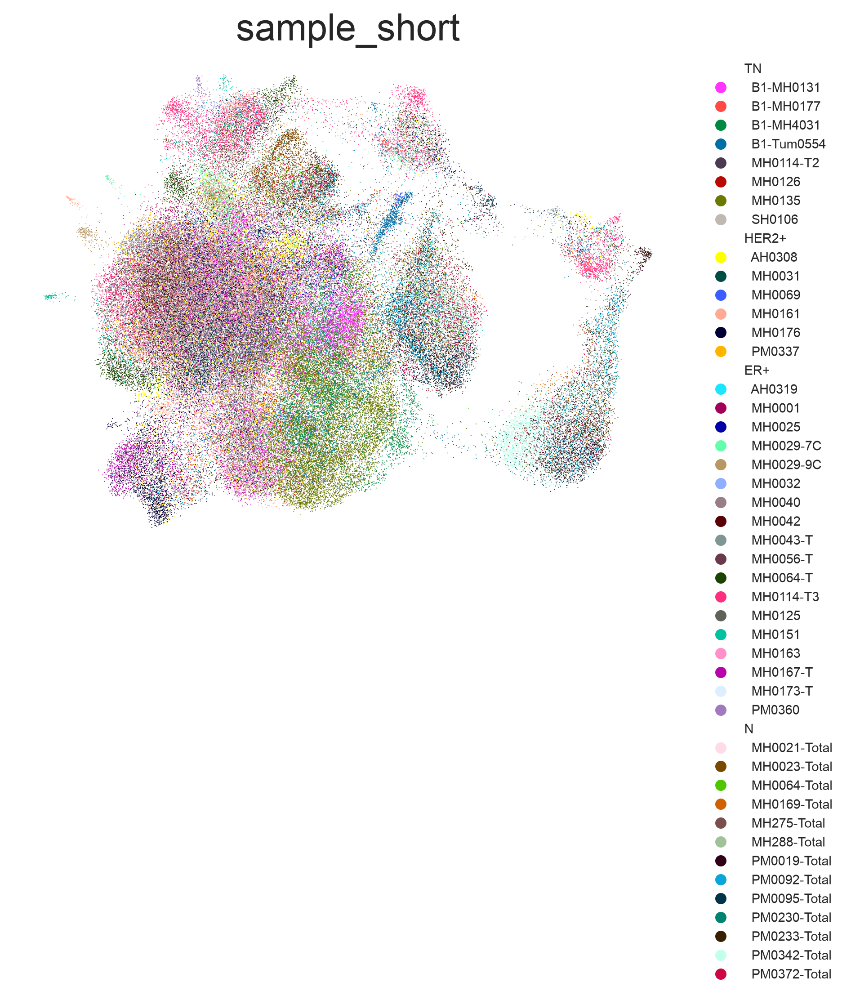

In [109]:
# samples coloured individually, with the legend grouped by condition
sc.pl.umap(epi, color="sample_short", legend_loc=None, frameon=False, show=False)

ax = plt.gca()

# read the colours scanpy just assigned, so the legend matches the plot
sample_to_color = dict(
    zip(epi.obs["sample_short"].cat.categories, epi.uns["sample_short_colors"])
)

handles = []

for condition in condition_order:

    handles.append(Line2D([], [], linestyle="none", label=condition, color="black"))

    for sample in sorted(epi.obs.loc[epi.obs["condition"] == condition, "sample_short"].unique()):
        handles.append(
            Line2D([], [], marker="o", linestyle="none", markersize=6,
                   markerfacecolor=sample_to_color[sample], markeredgecolor="none",
                   label=f"  {sample}")
        )

ax.legend(handles=handles, bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False, fontsize=7)

plt.savefig(fig_dir / "epithelial_umap_sample.png", dpi=300, bbox_inches="tight")
plt.show()

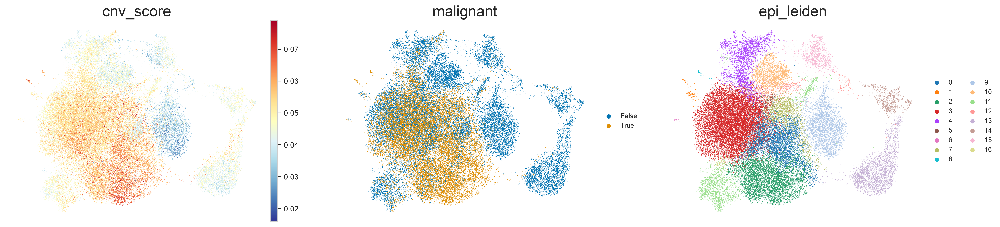

In [110]:
sc.pl.umap(
    epi,
    color=["cnv_score", "malignant", "epi_leiden"],
    ncols=3,
    cmap="RdYlBu_r",
    vmax="p99.9",
    frameon=False,
    show=False,
)

plt.savefig(fig_dir / "epithelial_umap_malignancy.png", dpi=300, bbox_inches="tight")
plt.show()

## Robustness appendix — does the protected gene list shape the latent space?



The Methods require the target and Gavish signature genes to be added to the
integration feature set, and they make up a substantial minority of it. A
reviewer can reasonably ask whether the latent structure was partly engineered
towards the biology analysed afterwards.

This appendix trains a second scVI model on the **4,000 deviance-ranked genes
only** and compares the two representations. inferCNV and the malignancy call
are not repeated: neither depends on the integration feature set. Neither are
the Gavish states in 003b, which are scored on the full expression matrix, nor
the antigen calls in 003c, which are raw counts. The only result that depends
on Leiden is the Figure 1d bubble plot, so `epi_leiden_deviance` is stored for
that sensitivity check.

UMAP appearance is deliberately not the comparison: embeddings can rotate and
rearrange while the underlying neighbourhoods are unchanged.
Two scVI models never agree exactly, even on identical input, so a
feature-set comparison is uninterpretable on its own. A third model is
therefore trained on the **same protected gene set with a different seed**,
to establish the run-to-run floor. The feature-set effect is only real if it
exceeds that floor.


In [111]:
epi_deviance = epi[:, epi.var["highly_variable_deviance"]].copy()

In [112]:

assert epi_deviance.n_vars == n_hvg_deviance

In [113]:

scvi.model.SCVI.setup_anndata(epi_deviance, layer="counts", batch_key="sample")

In [114]:

model_deviance = scvi.model.SCVI(
    epi_deviance,
    n_latent=20,
    n_layers=2,
    gene_likelihood='nb',
)

In [115]:

model_deviance.train(
    max_epochs=400,
    accelerator="mps",
    batch_size=1024,
    early_stopping=True,
    early_stopping_patience=20,
    early_stopping_min_delta=1.0,
)

/opt/miniconda3/envs/cap/lib/python3.11/site-packages/scvi/train/_trainrunner.py:98: UserWarning: `accelerator` has been set to `mps`. Please note that not all PyTorch/Jax operations are supported with this backend. as a result, some models might be slower and less accurate than usual. Please verify your analysis!Refer to https://github.com/pytorch/pytorch/issues/77764 for more details.
  accelerator, lightning_devices, device = parse_device_args(
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/opt/miniconda3/envs/cap/lib/python3.11/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/opt/miniconda3/envs/cap/

Epoch 175/400:  44%|████▍     | 175/400 [17:57<23:05,  6.16s/it, v_num=1, train_loss=2.78e+3]  
Monitored metric elbo_validation did not improve in the last 20 records. Best score: 2798.460. Signaling Trainer to stop.


In [116]:

model_deviance.history['elbo_train'].shape[0]

175

In [117]:
epi.obsm["X_scVI_deviance"] = model_deviance.get_latent_representation()

In [118]:
# free the large intermediates; nothing below uses them
del model_deviance
gc.collect()

126268

In [119]:

sc.pp.neighbors(
    epi,
    use_rep="X_scVI_deviance",
    n_neighbors=30,
    random_state=0,
    key_added="deviance_neighbors",
)

sc.tl.leiden(
    epi,
    resolution=0.5,
    key_added="epi_leiden_deviance",
    neighbors_key="deviance_neighbors",
    flavor="igraph",
    n_iterations=2,
    directed=False,
    random_state=0,
)

del epi_deviance
gc.collect()

computing neighbors
    finished (0:00:07)
running Leiden clustering
    finished (0:00:05)


782

In [120]:
# run-to-run floor: same genes as the primary model, different seed
epi_seed = epi[:, epi.var["highly_variable"]].copy()

scvi.settings.seed = 0 + 1

scvi.model.SCVI.setup_anndata(epi_seed, layer="counts", batch_key="sample")

model_seed = scvi.model.SCVI(
    epi_seed,
    n_latent=20,
    n_layers=2,
    gene_likelihood='nb',
)

model_seed.train(
    max_epochs=400,
    accelerator="mps",
    batch_size=1024,
    early_stopping=True,
    early_stopping_patience=20,
    early_stopping_min_delta=1.0,
)

epi.obsm["X_scVI_seed2"] = model_seed.get_latent_representation()

scvi.settings.seed = 0

sc.pp.neighbors(
    epi, use_rep="X_scVI_seed2", n_neighbors=30,
    random_state=0, key_added="seed2_neighbors",
)

sc.tl.leiden(
    epi, resolution=0.5, key_added="epi_leiden_seed2",
    neighbors_key="seed2_neighbors", flavor="igraph",
    n_iterations=2, directed=False, random_state=0,
)

del epi_seed
gc.collect()

Seed set to 1
/opt/miniconda3/envs/cap/lib/python3.11/site-packages/scvi/train/_trainrunner.py:98: UserWarning: `accelerator` has been set to `mps`. Please note that not all PyTorch/Jax operations are supported with this backend. as a result, some models might be slower and less accurate than usual. Please verify your analysis!Refer to https://github.com/pytorch/pytorch/issues/77764 for more details.
  accelerator, lightning_devices, device = parse_device_args(
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/opt/miniconda3/envs/cap/lib/python3.11/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/opt/minico

Epoch 206/400:  52%|█████▏    | 206/400 [22:59<21:38,  6.70s/it, v_num=1, train_loss=2.89e+3]
Monitored metric elbo_validation did not improve in the last 20 records. Best score: 2898.326. Signaling Trainer to stop.


Seed set to 0


computing neighbors
    finished (0:00:07)
running Leiden clustering
    finished (0:00:05)


782

In [121]:
# free the large intermediates; nothing below uses them
del model_seed
gc.collect()

2259

In [122]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from sklearn.neighbors import NearestNeighbors

k_overlap = 30
overlap_idx = eval_idx          # the same subsample used for the silhouettes


def knn_indices(representation):
    z = epi.obsm[representation][overlap_idx]
    nn = NearestNeighbors(n_neighbors=k_overlap + 1).fit(z)
    return nn.kneighbors(z, return_distance=False)[:, 1:]


nn_primary = knn_indices("X_scVI")

rows = []

for label, representation, clustering in [
    ("feature set (deviance-only)", "X_scVI_deviance", "epi_leiden_deviance"),
    ("seed only (run-to-run floor)", "X_scVI_seed2", "epi_leiden_seed2"),
]:

    nn_other = knn_indices(representation)

    overlap = np.array([
        len(set(a) & set(b)) / k_overlap for a, b in zip(nn_primary, nn_other)
    ])

    rows.append({
        "comparison_against_primary": label,
        "leiden_ari": adjusted_rand_score(epi.obs["epi_leiden"], epi.obs[clustering]),
        "leiden_nmi": normalized_mutual_info_score(epi.obs["epi_leiden"], epi.obs[clustering]),
        "knn_overlap_mean": overlap.mean(),
        "knn_overlap_median": float(np.median(overlap)),
        "n_clusters": int(epi.obs[clustering].nunique()),
    })

latent_comparison = pd.DataFrame(rows)

print(f"primary model: {int(epi.obs['epi_leiden'].nunique())} clusters\n")
print(latent_comparison.round(3).to_string(index=False))

print(
    "\nthe feature-set effect is only meaningful where it exceeds the seed-only floor"
)

latent_comparison.to_csv(df_dir / "scvi_latent_comparison.csv", index=False)

primary model: 17 clusters

  comparison_against_primary  leiden_ari  leiden_nmi  knn_overlap_mean  knn_overlap_median  n_clusters
 feature set (deviance-only)       0.608       0.680             0.412                 0.4          15
seed only (run-to-run floor)       0.663       0.678             0.401                 0.4          16

the feature-set effect is only meaningful where it exceeds the seed-only floor


In [123]:
# batch and biology separation in all three representations
rows = []

for label, representation in [
    ("protected (primary)", "X_scVI"),
    ("deviance_only", "X_scVI_deviance"),
    ("protected, seed 2", "X_scVI_seed2"),
]:

    z = epi.obsm[representation][eval_idx]

    rows.append({
        "model": label,
        "annotation_silhouette": silhouette_score(z, obs_eval["cl_annotation"]),
        "sample_silhouette": silhouette_score(z, obs_eval["sample"]),
        "condition_silhouette": silhouette_score(z, obs_eval["condition"].astype(str)),
    })

model_comparison = pd.DataFrame(rows)

print(model_comparison.round(3).to_string(index=False))

              model  annotation_silhouette  sample_silhouette  condition_silhouette
protected (primary)                  0.037             -0.067                 0.014
      deviance_only                  0.044             -0.069                 0.012
  protected, seed 2                  0.036             -0.068                 0.011


In [124]:
# free the large intermediates; nothing below uses them
del model
gc.collect()

0

In [125]:
# batch mixing measured within each annotation, so that biological separation is not mistaken for good mixing
rows = []

for annotation in obs_eval["cl_annotation"].value_counts().index:

    mask = (obs_eval["cl_annotation"] == annotation).to_numpy()

    if mask.sum() < 100 or obs_eval.loc[mask, "sample"].nunique() < 2:
        continue

    row = {"cl_annotation": annotation, "n_cells": int(mask.sum())}

    for label, representation in [
        ("protected", "X_scVI"),
        ("deviance_only", "X_scVI_deviance"),
        ("seed2", "X_scVI_seed2"),
    ]:
        row[label] = silhouette_score(
            epi.obsm[representation][eval_idx][mask], obs_eval.loc[mask, "sample"]
        )

    rows.append(row)

within_annotation = pd.DataFrame(rows)

print(within_annotation.round(3).to_string(index=False))

                 cl_annotation  n_cells  protected  deviance_only  seed2
    Epithelial: Mature Luminal     8971     -0.059         -0.055 -0.059
                    Epithelial     5789     -0.073         -0.078 -0.079
           Epithelial: Cycling     2562     -0.162         -0.151 -0.166
             Epithelial: Basal     2036     -0.111         -0.098 -0.109
Epithelial: Luminal Progenitor      642     -0.053         -0.051 -0.048


In [126]:
annotation_agreement = pd.crosstab(epi.obs["epi_leiden"], epi.obs["epi_leiden_deviance"])
best_match = annotation_agreement.max(axis=1) / annotation_agreement.sum(axis=1)

print("fraction of each primary cluster falling in a single deviance-only cluster")
print(best_match.round(3).sort_values().to_string())

feature_effect = latent_comparison.iloc[0]
seed_floor = latent_comparison.iloc[1]

epi.uns["protected_gene_sensitivity"] = {
    "question": "does adding target and Gavish genes to the scVI feature set "
                "change the epithelial latent structure beyond run-to-run variation",
    "primary_features": int(n_hvg),
    "deviance_only_features": int(n_hvg_deviance),
    "protected_added": int(n_protected_added),
    "protected_fraction": float(n_protected_added / n_hvg),
    "feature_set_ari": float(feature_effect["leiden_ari"]),
    "seed_floor_ari": float(seed_floor["leiden_ari"]),
    "feature_set_knn_overlap": float(feature_effect["knn_overlap_mean"]),
    "seed_floor_knn_overlap": float(seed_floor["knn_overlap_mean"]),
    "k": int(k_overlap),
}

model_comparison.to_csv(df_dir / "scvi_protected_gene_sensitivity.csv", index=False)
within_annotation.to_csv(df_dir / "scvi_protected_gene_sensitivity_by_annotation.csv", index=False)
best_match.rename("largest_matching_fraction").to_csv(
    df_dir / "scvi_protected_gene_cluster_correspondence.csv"
)

fraction of each primary cluster falling in a single deviance-only cluster
epi_leiden
0     0.392
4     0.574
1     0.659
7     0.666
8     0.710
12    0.789
5     0.809
2     0.849
11    0.882
16    0.892
3     0.896
10    0.921
6     0.943
9     0.948
15    0.971
13    0.978
14    0.981


## Save

In [127]:
# nothing in this notebook may alter the raw counts
final_positive = {
    g: int((np.asarray(epi[:, g].layers["counts"].todense()).ravel() > 0).sum())
    for g in target_genes
}

assert epi.n_obs == n_cells_start
assert epi.n_vars == n_genes_start
assert final_positive == {g: baseline_positive[g] for g in final_positive}

print(epi)

AnnData object with n_obs × n_vars = 129599 × 27357
    obs: 'sample', 'condition', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'S_score', 'G2M_score', 'phase', 'doublet_score', 'doublet_class', 'batch', 'patient', 'sample_short', 'celltypist_pal_label', 'celltypist_pal_conf', 'cl_annotation', 'cnv_score', 'cnv_signal', 'cnv_high', 'malignant', 'leiden_r0.5', 'leiden_r1.0', 'leiden_r1.2', 'leiden_r1.5', 'epi_leiden', 'epi_leiden_deviance', 'epi_leiden_seed2'
    var: 'gene_id', 'feature_type', 'mt', 'ribo', 'hb', 'n_cells', 'binomial_deviance', 'highly_variable_atlas', 'highly_variable_deviance', 'highly_variable'
    uns: 'celltypist_pal_label_colors', 'cl_annotation_colors', 'condition_colors', 'patient_colors', 'sample_colors'

In [ ]:
epi.uns["epithelial_integration"] = {
    "hvg_method": "binomial deviance (scry), max across samples",
    "n_hvg_deviance": int(4000),
    "n_hvg_total": int(n_hvg),
    "protected_genes": "ROR1, EGFR, ERBB2, EPCAM, ROR2 and Gavish cancer meta-programme genes",
    "scvi_n_latent": int(20),
    "scvi_n_layers": int(2),
    "scvi_gene_likelihood": 'nb',
    "scvi_batch_key": "sample",
    "scvi_epochs": int(n_epochs),
    "n_neighbors": int(30),
    "leiden_resolutions": [float(x) for x in leiden_resolutions],
    "leiden_primary": float(0.5),
    "seed": int(0),
}

In [129]:
out_path = save_dir / "epithelial_malignancy_scvi.h5ad"

for name in list(epi.layers.keys()):
    if not sp.issparse(epi.layers[name]):
        epi.layers[name] = sp.csr_matrix(epi.layers[name])

if not sp.issparse(epi.X):
    epi.X = sp.csr_matrix(epi.X)

# write to a temporary file first, so an interrupted write cannot destroy the object
tmp_path = out_path.with_suffix(".h5ad.tmp")

epi.write_h5ad(tmp_path, compression="gzip")
os.replace(tmp_path, out_path)

print(out_path.name)

epithelial_malignancy_scvi.h5ad


In [130]:
check = sc.read_h5ad(out_path, backed="r")

assert check.n_obs == epi.n_obs
assert check.n_vars == epi.n_vars

check.shape

(129599, 27357)

In [131]:

del check
gc.collect()

1105

In [132]:
# session_info.show() has exhausted the kernel on the larger objects in this project, so the versions that matter are recorded directly
import sys
from importlib.metadata import version, PackageNotFoundError

packages = [
    "scanpy", "anndata", "scvi-tools", "numpy", "pandas", "scipy", "scikit-learn",
    "matplotlib", "seaborn", "statsmodels", "infercnvpy", "leidenalg", "igraph",
    "rpy2", "papermill", "session-info",
]

versions = {"python": sys.version.split()[0]}

for name in packages:
    try:
        versions[name] = version(name)
    except PackageNotFoundError:
        continue

pd.Series(versions, name="version").to_frame()

,version
python,3.11.15
scanpy,1.11.5
anndata,0.12.19
scvi-tools,1.4.2
numpy,2.4.6
pandas,2.3.3
scipy,1.17.1
scikit-learn,1.9.0
matplotlib,3.11.1
seaborn,0.13.2
